In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Columns in dataset:")
print(df.columns.tolist())

Columns in dataset:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [5]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [6]:
print("First 5 records:")
display(df.head())

print("Last 5 records:")
display(df.tail())

First 5 records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Last 5 records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [7]:
rows, columns = df.shape

print("Total Rows:", rows)
print("Total Columns:", columns)

Total Rows: 7043
Total Columns: 21


In [8]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

Missing values in each column:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


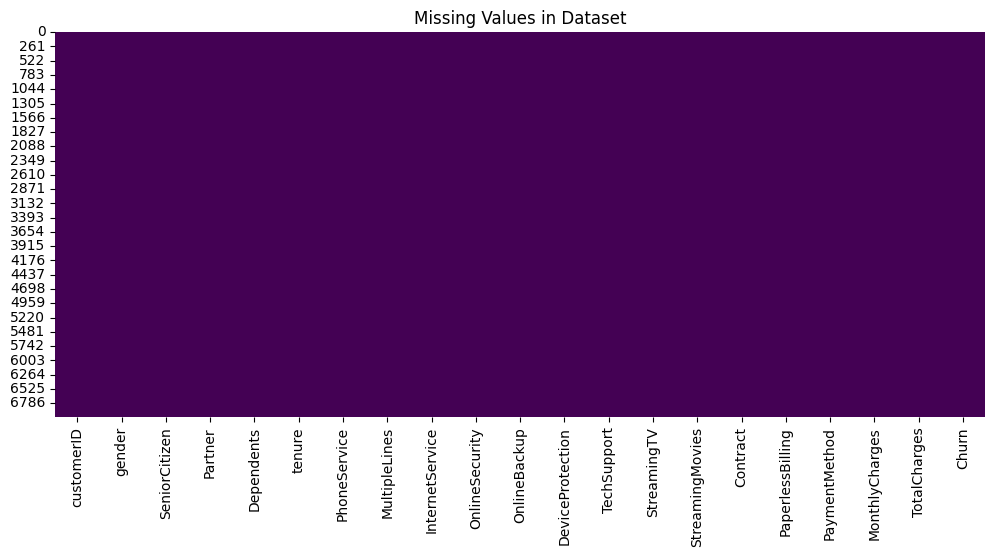

In [9]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values in Dataset")
plt.show()

In [10]:
duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 0


In [11]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges
count,7043.000000,7043.000000
mean,32.371149,64.761692
std,24.559481,30.090047
min,0.000000,18.250000
25%,9.000000,35.500000
50%,29.000000,70.350000
75%,55.000000,89.850000
max,72.000000,118.750000


In [12]:
print("Unique Customers:", df["customerID"].nunique())
print("Unique Contracts:", df["Contract"].nunique())
print("Unique Internet Services:", df["InternetService"].nunique())
print("Unique Payment Methods:", df["PaymentMethod"].nunique())
print("Unique Churn Values:", df["Churn"].nunique())

Unique Customers: 7043
Unique Contracts: 3
Unique Internet Services: 3
Unique Payment Methods: 4
Unique Churn Values: 2


In [13]:
df_clean = df.copy()

print("Working copy created.")

Working copy created.


In [14]:
df_clean.columns = df_clean.columns.str.strip()

print(df_clean.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [15]:
print("Missing values before handling:")
display(df_clean.isnull().sum())

Missing values before handling:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [16]:
# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Fill missing TotalCharges with 0
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

# Fill other missing values
df_clean = df_clean.fillna("Unknown")

print("Missing values handled.")

display(df_clean.isnull().sum())

Missing values handled.


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [17]:
df_clean["tenure"] = pd.to_numeric(
    df_clean["tenure"],
    errors="coerce"
)

df_clean["MonthlyCharges"] = pd.to_numeric(
    df_clean["MonthlyCharges"],
    errors="coerce"
)

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

print(df_clean.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [18]:
df_clean = df_clean.dropna(
    subset=["tenure", "MonthlyCharges", "TotalCharges"]
)

print("Invalid numeric records removed.")
print("Remaining records:", len(df_clean))

Invalid numeric records removed.
Remaining records: 7043


In [19]:
df_clean["ChurnFlag"] = (
    df_clean["Churn"] == "Yes"
).astype(int)

print("Churned customers:", df_clean["ChurnFlag"].sum())
print("Non-churned customers:", (df_clean["ChurnFlag"] == 0).sum())

display(df_clean[["customerID", "Churn", "ChurnFlag"]].head())

Churned customers: 1869
Non-churned customers: 5174


,customerID,Churn,ChurnFlag
0,7590-VHVEG,No,0
1,5575-GNVDE,No,0
2,3668-QPYBK,Yes,1
3,7795-CFOCW,No,0
4,9237-HQITU,Yes,1


In [20]:
df_analysis = df_clean.copy()

print("Analysis dataset created.")
print("Records:", len(df_analysis))

Analysis dataset created.
Records: 7043


In [21]:
Q1 = df_analysis["MonthlyCharges"].quantile(0.25)
Q3 = df_analysis["MonthlyCharges"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_analysis["ChargeOutlier"] = (
    (df_analysis["MonthlyCharges"] < lower_bound) |
    (df_analysis["MonthlyCharges"] > upper_bound)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("Charge outliers detected:", df_analysis["ChargeOutlier"].sum())

Q1: 35.5
Q3: 89.85
IQR: 54.349999999999994
Lower Bound: -46.02499999999999
Upper Bound: 171.375
Charge outliers detected: 0


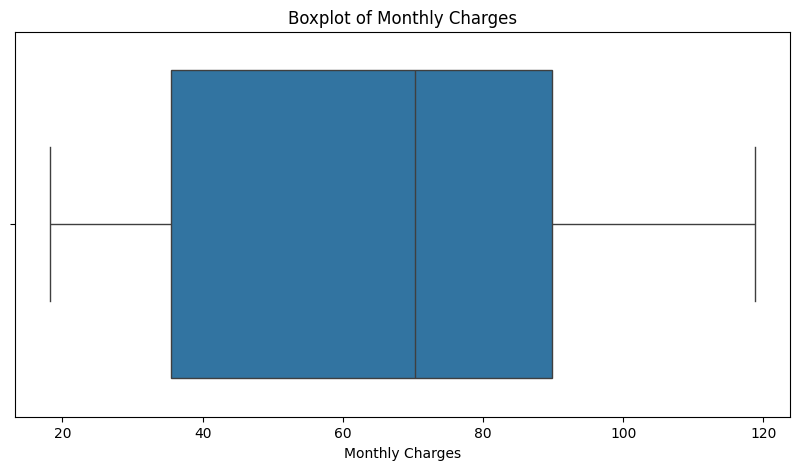

In [22]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_analysis["MonthlyCharges"])

plt.title("Boxplot of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.show()

In [23]:
customer_data = df_analysis[
    [
        "customerID",
        "gender",
        "SeniorCitizen",
        "Partner",
        "Dependents",
        "tenure",
        "Churn"
    ]
].drop_duplicates()

customer_data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No
1,5575-GNVDE,Male,0,No,No,34,No
2,3668-QPYBK,Male,0,No,No,2,Yes
3,7795-CFOCW,Male,0,No,No,45,No
4,9237-HQITU,Female,0,No,No,2,Yes


In [27]:
# Extract service columns to define service_data
service_columns = [
    "customerID", "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling",
    "PaymentMethod", "MonthlyCharges", "TotalCharges"
]
service_data = df_analysis[service_columns].drop_duplicates()

# Perform the merge
integrated_data = pd.merge(
    customer_data,
    service_data,
    on="customerID",
    how="left"
)

print("Integrated dataset created successfully.")
display(integrated_data.head())

Integrated dataset created successfully.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,Churn,PhoneService,MultipleLines,InternetService,...,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,Female,0,Yes,No,1,No,No,No phone service,DSL,...,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,Male,0,No,No,34,No,Yes,No,DSL,...,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,3668-QPYBK,Male,0,No,No,2,Yes,Yes,No,DSL,...,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,Male,0,No,No,45,No,No,No phone service,DSL,...,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,Female,0,No,No,2,Yes,Yes,No,Fiber optic,...,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [28]:
df_analysis["CustomerValue"] = df_analysis["TotalCharges"]

print("Customer value calculated successfully!")

display(
    df_analysis[
        ["customerID", "MonthlyCharges", "TotalCharges", "CustomerValue"]
    ].head(10)
)

Customer value calculated successfully!


,customerID,MonthlyCharges,TotalCharges,CustomerValue
0,7590-VHVEG,29.85,29.85,29.85
1,5575-GNVDE,56.95,1889.50,1889.50
2,3668-QPYBK,53.85,108.15,108.15
3,7795-CFOCW,42.30,1840.75,1840.75
4,9237-HQITU,70.70,151.65,151.65
5,9305-CDSKC,99.65,820.50,820.50
6,1452-KIOVK,89.10,1949.40,1949.40
7,6713-OKOMC,29.75,301.90,301.90
8,7892-POOKP,104.80,3046.05,3046.05
9,6388-TABGU,56.15,3487.95,3487.95


In [29]:
df_analysis["TenureYears"] = (
    df_analysis["tenure"] / 12
)

df_analysis["TenureCategory"] = pd.cut(
    df_analysis["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)

display(
    df_analysis[
        ["customerID", "tenure", "TenureYears", "TenureCategory"]
    ].head(10)
)

,customerID,tenure,TenureYears,TenureCategory
0,7590-VHVEG,1,0.083333,0-12 Months
1,5575-GNVDE,34,2.833333,25-48 Months
2,3668-QPYBK,2,0.166667,0-12 Months
3,7795-CFOCW,45,3.750000,25-48 Months
4,9237-HQITU,2,0.166667,0-12 Months
5,9305-CDSKC,8,0.666667,0-12 Months
6,1452-KIOVK,22,1.833333,13-24 Months
7,6713-OKOMC,10,0.833333,0-12 Months
8,7892-POOKP,28,2.333333,25-48 Months
9,6388-TABGU,62,5.166667,49-72 Months


In [30]:
customer_metrics = df_analysis.groupby("customerID").agg(
    TenureMonths=("tenure", "max"),
    MonthlyRevenue=("MonthlyCharges", "mean"),
    TotalRevenue=("TotalCharges", "sum"),
    AverageMonthlyCharge=("MonthlyCharges", "mean"),
    Churn=("ChurnFlag", "max")
).reset_index()

print("Customer-level metrics calculated successfully!")

display(customer_metrics.head(10))

Customer-level metrics calculated successfully!


,customerID,TenureMonths,MonthlyRevenue,TotalRevenue,AverageMonthlyCharge,Churn
0,0002-ORFBO,9,65.60,593.30,65.60,0
1,0003-MKNFE,9,59.90,542.40,59.90,0
2,0004-TLHLJ,4,73.90,280.85,73.90,1
3,0011-IGKFF,13,98.00,1237.85,98.00,1
4,0013-EXCHZ,3,83.90,267.40,83.90,1
5,0013-MHZWF,9,69.40,571.45,69.40,0
6,0013-SMEOE,71,109.70,7904.25,109.70,0
7,0014-BMAQU,63,84.65,5377.80,84.65,0
8,0015-UOCOJ,7,48.20,340.35,48.20,0
9,0016-QLJIS,65,90.45,5957.90,90.45,0


In [31]:
customer_metrics["CustomerValueCategory"] = pd.qcut(
    customer_metrics["TotalRevenue"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

customer_metrics["TenureCategory"] = pd.cut(
    customer_metrics["TenureMonths"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New", "Short-term", "Medium-term", "Long-term"]
)

display(
    customer_metrics[
        [
            "customerID",
            "TenureMonths",
            "TotalRevenue",
            "CustomerValueCategory",
            "TenureCategory"
        ]
    ].head(10)
)

,customerID,TenureMonths,TotalRevenue,CustomerValueCategory,TenureCategory
0,0002-ORFBO,9,593.30,Low,New
1,0003-MKNFE,9,542.40,Low,New
2,0004-TLHLJ,4,280.85,Low,New
3,0011-IGKFF,13,1237.85,Medium,Short-term
4,0013-EXCHZ,3,267.40,Low,New
5,0013-MHZWF,9,571.45,Low,New
6,0013-SMEOE,71,7904.25,High,Long-term
7,0014-BMAQU,63,5377.80,High,Long-term
8,0015-UOCOJ,7,340.35,Low,New
9,0016-QLJIS,65,5957.90,High,Long-term


In [32]:
customer_data = customer_data.drop_duplicates(
    subset=["customerID"]
)

customer_data = pd.merge(
    customer_data,
    customer_metrics,
    on="customerID",
    how="left"
)

print("Customer data integration completed!")

display(customer_data.head(10))

print("Total customers:", len(customer_data))
print("Total columns:", len(customer_data.columns))

Customer data integration completed!


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,Churn_x,TenureMonths,MonthlyRevenue,TotalRevenue,AverageMonthlyCharge,Churn_y,CustomerValueCategory,TenureCategory
0,7590-VHVEG,Female,0,Yes,No,1,No,1,29.85,29.85,29.85,0,Low,New
1,5575-GNVDE,Male,0,No,No,34,No,34,56.95,1889.50,56.95,0,Medium,Medium-term
2,3668-QPYBK,Male,0,No,No,2,Yes,2,53.85,108.15,53.85,1,Low,New
3,7795-CFOCW,Male,0,No,No,45,No,45,42.30,1840.75,42.30,0,Medium,Medium-term
4,9237-HQITU,Female,0,No,No,2,Yes,2,70.70,151.65,70.70,1,Low,New
5,9305-CDSKC,Female,0,No,No,8,Yes,8,99.65,820.50,99.65,1,Medium,New
6,1452-KIOVK,Male,0,No,Yes,22,No,22,89.10,1949.40,89.10,0,Medium,Short-term
7,6713-OKOMC,Female,0,No,No,10,No,10,29.75,301.90,29.75,0,Low,New
8,7892-POOKP,Female,0,Yes,No,28,Yes,28,104.80,3046.05,104.80,1,High,Medium-term
9,6388-TABGU,Male,0,No,Yes,62,No,62,56.15,3487.95,56.15,0,High,Long-term


Total customers: 7043
Total columns: 14


In [33]:
dim_customer = customer_data.copy()

dim_customer = dim_customer.reset_index(drop=True)

dim_customer["CustomerKey"] = range(
    1, len(dim_customer) + 1
)

display(dim_customer.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,Churn_x,TenureMonths,MonthlyRevenue,TotalRevenue,AverageMonthlyCharge,Churn_y,CustomerValueCategory,TenureCategory,CustomerKey
0,7590-VHVEG,Female,0,Yes,No,1,No,1,29.85,29.85,29.85,0,Low,New,1
1,5575-GNVDE,Male,0,No,No,34,No,34,56.95,1889.50,56.95,0,Medium,Medium-term,2
2,3668-QPYBK,Male,0,No,No,2,Yes,2,53.85,108.15,53.85,1,Low,New,3
3,7795-CFOCW,Male,0,No,No,45,No,45,42.30,1840.75,42.30,0,Medium,Medium-term,4
4,9237-HQITU,Female,0,No,No,2,Yes,2,70.70,151.65,70.70,1,Low,New,5


In [34]:
dim_service = service_data.copy()

dim_service = dim_service.reset_index(drop=True)

dim_service["ServiceKey"] = range(
    1, len(dim_service) + 1
)

display(dim_service.head())

,customerID,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,ServiceKey
0,7590-VHVEG,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,1
1,5575-GNVDE,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,2
2,3668-QPYBK,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,3
3,7795-CFOCW,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,4
4,9237-HQITU,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,5


In [36]:
# Extract billing columns to define billing_data
billing_columns = [
    "customerID", "Contract", "PaperlessBilling",
    "PaymentMethod", "MonthlyCharges", "TotalCharges"
]
billing_data = df_analysis[billing_columns].drop_duplicates()

dim_billing = billing_data.copy()
dim_billing = dim_billing.reset_index(drop=True)

dim_billing["BillingKey"] = range(
    1, len(dim_billing) + 1
)

display(dim_billing.head())

,customerID,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,BillingKey
0,7590-VHVEG,Month-to-month,Yes,Electronic check,29.85,29.85,1
1,5575-GNVDE,One year,No,Mailed check,56.95,1889.50,2
2,3668-QPYBK,Month-to-month,Yes,Mailed check,53.85,108.15,3
3,7795-CFOCW,One year,No,Bank transfer (automatic),42.30,1840.75,4
4,9237-HQITU,Month-to-month,Yes,Electronic check,70.70,151.65,5


In [37]:
fact_customer = df_analysis[
    [
        "customerID",
        "MonthlyCharges",
        "TotalCharges",
        "tenure",
        "ChurnFlag"
    ]
].copy()

print("Fact table created successfully!")

display(fact_customer.head(10))

Fact table created successfully!


,customerID,MonthlyCharges,TotalCharges,tenure,ChurnFlag
0,7590-VHVEG,29.85,29.85,1,0
1,5575-GNVDE,56.95,1889.50,34,0
2,3668-QPYBK,53.85,108.15,2,1
3,7795-CFOCW,42.30,1840.75,45,0
4,9237-HQITU,70.70,151.65,2,1
5,9305-CDSKC,99.65,820.50,8,1
6,1452-KIOVK,89.10,1949.40,22,0
7,6713-OKOMC,29.75,301.90,10,0
8,7892-POOKP,104.80,3046.05,28,1
9,6388-TABGU,56.15,3487.95,62,0


In [38]:
fact_customer = df_analysis[
    [
        "customerID",
        "MonthlyCharges",
        "TotalCharges",
        "tenure",
        "ChurnFlag"
    ]
].copy()

print("Fact table created successfully!")

display(fact_customer.head(10))

Fact table created successfully!


,customerID,MonthlyCharges,TotalCharges,tenure,ChurnFlag
0,7590-VHVEG,29.85,29.85,1,0
1,5575-GNVDE,56.95,1889.50,34,0
2,3668-QPYBK,53.85,108.15,2,1
3,7795-CFOCW,42.30,1840.75,45,0
4,9237-HQITU,70.70,151.65,2,1
5,9305-CDSKC,99.65,820.50,8,1
6,1452-KIOVK,89.10,1949.40,22,0
7,6713-OKOMC,29.75,301.90,10,0
8,7892-POOKP,104.80,3046.05,28,1
9,6388-TABGU,56.15,3487.95,62,0


In [39]:
customer_key_map = dim_customer.set_index(
    "customerID"
)["CustomerKey"]

service_key_map = dim_service.set_index(
    "customerID"
)["ServiceKey"]

billing_key_map = dim_billing.set_index(
    "customerID"
)["BillingKey"]

fact_customer["CustomerKey"] = (
    fact_customer["customerID"].map(customer_key_map)
)

fact_customer["ServiceKey"] = (
    fact_customer["customerID"].map(service_key_map)
)

fact_customer["BillingKey"] = (
    fact_customer["customerID"].map(billing_key_map)
)

print("Dimension keys generated and mapped!")
display(fact_customer.head())

Dimension keys generated and mapped!


,customerID,MonthlyCharges,TotalCharges,tenure,ChurnFlag,CustomerKey,ServiceKey,BillingKey
0,7590-VHVEG,29.85,29.85,1,0,1,1,1
1,5575-GNVDE,56.95,1889.50,34,0,2,2,2
2,3668-QPYBK,53.85,108.15,2,1,3,3,3
3,7795-CFOCW,42.30,1840.75,45,0,4,4,4
4,9237-HQITU,70.70,151.65,2,1,5,5,5


In [40]:
fact_customer = fact_customer[
    [
        "CustomerKey",
        "ServiceKey",
        "BillingKey",
        "MonthlyCharges",
        "TotalCharges",
        "tenure",
        "ChurnFlag"
    ]
].copy()

fact_customer = fact_customer.dropna(
    subset=["CustomerKey", "ServiceKey", "BillingKey"]
)

fact_customer["CustomerKey"] = fact_customer["CustomerKey"].astype(int)
fact_customer["ServiceKey"] = fact_customer["ServiceKey"].astype(int)
fact_customer["BillingKey"] = fact_customer["BillingKey"].astype(int)

print("Final Fact Table Created Successfully!")

display(fact_customer.head(10))

print("Fact Table Shape:", fact_customer.shape)

Final Fact Table Created Successfully!


,CustomerKey,ServiceKey,BillingKey,MonthlyCharges,TotalCharges,tenure,ChurnFlag
0,1,1,1,29.85,29.85,1,0
1,2,2,2,56.95,1889.50,34,0
2,3,3,3,53.85,108.15,2,1
3,4,4,4,42.30,1840.75,45,0
4,5,5,5,70.70,151.65,2,1
5,6,6,6,99.65,820.50,8,1
6,7,7,7,89.10,1949.40,22,0
7,8,8,8,29.75,301.90,10,0
8,9,9,9,104.80,3046.05,28,1
9,10,10,10,56.15,3487.95,62,0


Fact Table Shape: (7043, 7)


In [41]:
print("========== DATA WAREHOUSE SUMMARY ==========")

print("\nFACT TABLE")
print("Fact Customer:", fact_customer.shape)

print("\nDIMENSION TABLES")
print("Customer Dimension:", dim_customer.shape)
print("Service Dimension:", dim_service.shape)
print("Billing Dimension:", dim_billing.shape)

print("\nPRIMARY KEY VALIDATION")

print("Unique Customer Keys:", dim_customer["CustomerKey"].nunique())
print("Unique Service Keys:", dim_service["ServiceKey"].nunique())
print("Unique Billing Keys:", dim_billing["BillingKey"].nunique())

print("\nFOREIGN KEY VALIDATION")

print("Customer Key Matches:",
      fact_customer["CustomerKey"].isin(dim_customer["CustomerKey"]).all())

print("Service Key Matches:",
      fact_customer["ServiceKey"].isin(dim_service["ServiceKey"]).all())

print("Billing Key Matches:",
      fact_customer["BillingKey"].isin(dim_billing["BillingKey"]).all())

print("\nStar Schema verification completed!")

========== DATA WAREHOUSE SUMMARY ==========

FACT TABLE
Fact Customer: (7043, 7)

DIMENSION TABLES
Customer Dimension: (7043, 15)
Service Dimension: (7043, 16)
Billing Dimension: (7043, 7)

PRIMARY KEY VALIDATION
Unique Customer Keys: 7043
Unique Service Keys: 7043
Unique Billing Keys: 7043

FOREIGN KEY VALIDATION
Customer Key Matches: True
Service Key Matches: True
Billing Key Matches: True

Star Schema verification completed!


In [42]:
customer_metrics["TenureCategory"] = pd.cut(
    customer_metrics["TenureMonths"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New", "Short-term", "Medium-term", "Long-term"]
)

customer_metrics["RevenueCategory"] = pd.qcut(
    customer_metrics["TotalRevenue"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

customer_metrics["ChurnCategory"] = customer_metrics["Churn"].map({
    0: "Active",
    1: "Churned"
})

print("Customer discretization completed!")

display(
    customer_metrics[
        [
            "customerID",
            "TenureMonths",
            "TenureCategory",
            "TotalRevenue",
            "RevenueCategory",
            "ChurnCategory"
        ]
    ].head(10)
)

Customer discretization completed!


,customerID,TenureMonths,TenureCategory,TotalRevenue,RevenueCategory,ChurnCategory
0,0002-ORFBO,9,New,593.30,Low,Active
1,0003-MKNFE,9,New,542.40,Low,Active
2,0004-TLHLJ,4,New,280.85,Low,Churned
3,0011-IGKFF,13,Short-term,1237.85,Medium,Churned
4,0013-EXCHZ,3,New,267.40,Low,Churned
5,0013-MHZWF,9,New,571.45,Low,Active
6,0013-SMEOE,71,Long-term,7904.25,High,Active
7,0014-BMAQU,63,Long-term,5377.80,High,Active
8,0015-UOCOJ,7,New,340.35,Low,Active
9,0016-QLJIS,65,Long-term,5957.90,High,Active


In [44]:
# To make the cell repeatable, drop the columns if they already exist in customer_data
cols_to_merge = ["TenureCategory", "RevenueCategory", "ChurnCategory"]
customer_data = customer_data.drop(columns=[col for col in cols_to_merge if col in customer_data.columns])

# Perform the merge cleanly
customer_data = pd.merge(
    customer_data,
    customer_metrics[["customerID"] + cols_to_merge],
    on="customerID",
    how="left"
)

print("Customer segmentation integrated successfully!")

display(
    customer_data[["customerID"] + cols_to_merge].head(10)
)

Customer segmentation integrated successfully!


,customerID,TenureCategory,RevenueCategory,ChurnCategory
0,7590-VHVEG,New,Low,Active
1,5575-GNVDE,Medium-term,Medium,Active
2,3668-QPYBK,New,Low,Churned
3,7795-CFOCW,Medium-term,Medium,Active
4,9237-HQITU,New,Low,Churned
5,9305-CDSKC,New,Medium,Churned
6,1452-KIOVK,Short-term,Medium,Active
7,6713-OKOMC,New,Low,Active
8,7892-POOKP,Medium-term,High,Churned
9,6388-TABGU,Long-term,High,Active


In [46]:
print("========== DATA QUALITY REPORT ==========")

print("\n1. FACT TABLE")
print("Missing values:")
display(fact_customer.isnull().sum())

print("Duplicate records:", fact_customer.duplicated().sum())

print("\n2. CUSTOMER DIMENSION")
print("Missing values:")
display(dim_customer.isnull().sum())

print("Duplicate Customer IDs:",
      dim_customer["customerID"].duplicated().sum())

print("\n3. SERVICE DIMENSION")
print("Missing values:")
display(dim_service.isnull().sum())

print("Duplicate Customer IDs:",
      dim_service["customerID"].duplicated().sum())

print("\n4. BILLING DIMENSION")
print("Missing values:")
display(dim_billing.isnull().sum())

print("Duplicate Customer IDs:",
      dim_billing["customerID"].duplicated().sum())

========== DATA QUALITY REPORT ==========

1. FACT TABLE
Missing values:


,0
CustomerKey,0
ServiceKey,0
BillingKey,0
MonthlyCharges,0
TotalCharges,0
tenure,0
ChurnFlag,0


Duplicate records: 0

2. CUSTOMER DIMENSION
Missing values:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
Churn_x,0
TenureMonths,0
MonthlyRevenue,0
TotalRevenue,0


Duplicate Customer IDs: 0

3. SERVICE DIMENSION
Missing values:


,0
customerID,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0
DeviceProtection,0
TechSupport,0
StreamingTV,0
StreamingMovies,0


Duplicate Customer IDs: 0

4. BILLING DIMENSION
Missing values:


,0
customerID,0
Contract,0
PaperlessBilling,0
PaymentMethod,0
MonthlyCharges,0
TotalCharges,0
BillingKey,0


Duplicate Customer IDs: 0


In [47]:
fact_customer.to_csv("fact_customer.csv", index=False)

dim_customer.to_csv("dim_customer.csv", index=False)

dim_service.to_csv("dim_service.csv", index=False)

dim_billing.to_csv("dim_billing.csv", index=False)

print("All Data Warehouse tables exported successfully!")

print("Files saved:")
print("1. fact_customer.csv")
print("2. dim_customer.csv")
print("3. dim_service.csv")
print("4. dim_billing.csv")

All Data Warehouse tables exported successfully!
Files saved:
1. fact_customer.csv
2. dim_customer.csv
3. dim_service.csv
4. dim_billing.csv


In [48]:
olap_data = df_analysis.copy()

print("OLAP dataset prepared!")
display(olap_data.head())

OLAP dataset prepared!


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag,ChargeOutlier,CustomerValue,TenureYears,TenureCategory
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,Yes,Electronic check,29.85,29.85,No,0,False,29.85,0.083333,0-12 Months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,Mailed check,56.95,1889.50,No,0,False,1889.50,2.833333,25-48 Months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,Yes,Mailed check,53.85,108.15,Yes,1,False,108.15,0.166667,0-12 Months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,Bank transfer (automatic),42.30,1840.75,No,0,False,1840.75,3.750000,25-48 Months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,Yes,Electronic check,70.70,151.65,Yes,1,False,151.65,0.166667,0-12 Months


In [49]:
rollup_result = olap_data.groupby("Contract").agg(
    TotalCustomers=("customerID", "nunique"),
    TotalRevenue=("TotalCharges", "sum"),
    AverageMonthlyCharges=("MonthlyCharges", "mean"),
    TotalChurn=("ChurnFlag", "sum")
).reset_index()

print("OLAP Roll-up: Contract Summary")

display(rollup_result)

OLAP Roll-up: Contract Summary


,Contract,TotalCustomers,TotalRevenue,AverageMonthlyCharges,TotalChurn
0,Month-to-month,3875,5305861.5,66.398490,1655
1,One year,1473,4467053.5,65.048608,166
2,Two year,1695,6283253.7,60.770413,48


In [50]:
drilldown_result = olap_data.groupby(
    ["Contract", "InternetService"]
).agg(
    TotalCustomers=("customerID", "nunique"),
    TotalRevenue=("TotalCharges", "sum"),
    TotalChurn=("ChurnFlag", "sum")
).reset_index()

print("OLAP Drill-down: Contract and Internet Service")

display(drilldown_result)

OLAP Drill-down: Contract and Internet Service


,Contract,InternetService,TotalCustomers,TotalRevenue,TotalChurn
0,Month-to-month,DSL,1223,1015136.20,394
1,Month-to-month,Fiber optic,2128,4191552.55,1162
2,Month-to-month,No,524,99172.75,99
3,One year,DSL,570,1439990.85,53
4,One year,Fiber optic,539,2800424.35,104
5,One year,No,364,226638.30,9
6,Two year,DSL,628,2666283.80,12
7,Two year,Fiber optic,429,2931646.05,31
8,Two year,No,638,685323.85,5


In [51]:
selected_contract = "Month-to-month"

slice_result = olap_data[
    olap_data["Contract"] == selected_contract
]

slice_summary = slice_result.groupby("InternetService").agg(
    TotalCustomers=("customerID", "nunique"),
    TotalRevenue=("TotalCharges", "sum"),
    TotalChurn=("ChurnFlag", "sum")
).reset_index()

print("OLAP Slice Operation")
print("Selected Contract:", selected_contract)

display(slice_summary)

OLAP Slice Operation
Selected Contract: Month-to-month


,InternetService,TotalCustomers,TotalRevenue,TotalChurn
0,DSL,1223,1015136.20,394
1,Fiber optic,2128,4191552.55,1162
2,No,524,99172.75,99


In [53]:
selected_contract = "Month-to-month"

slice_result = olap_data[
    olap_data["Contract"] == selected_contract
]

slice_summary = slice_result.groupby("InternetService").agg(
    TotalCustomers=("customerID", "nunique"),
    TotalRevenue=("TotalCharges", "sum"),
    TotalChurn=("ChurnFlag", "sum")
).reset_index()

print("OLAP Slice Operation")
print("Selected Contract:", selected_contract)

display(slice_summary)

OLAP Slice Operation
Selected Contract: Month-to-month


,InternetService,TotalCustomers,TotalRevenue,TotalChurn
0,DSL,1223,1015136.20,394
1,Fiber optic,2128,4191552.55,1162
2,No,524,99172.75,99


In [54]:
pivot_result = olap_data.pivot_table(
    index="Contract",
    columns="InternetService",
    values="MonthlyCharges",
    aggfunc="mean",
    fill_value=0
)

print("OLAP Pivot Operation: Contract-wise Monthly Charges")

display(pivot_result)

OLAP Pivot Operation: Contract-wise Monthly Charges


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,50.219501,87.021194,20.409542
One year,61.396754,98.779499,20.819505
Two year,70.462978,104.571445,21.777351


In [55]:
features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "MonthlyCharges",
    "TotalCharges"
]

X = df_analysis[features]

y = df_analysis["ChurnFlag"]

print("Features and target selected.")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features and target selected.
Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
ChurnFlag
0    5174
1    1869
Name: count, dtype: int64


In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split completed!")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Dataset split completed!
Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
ChurnFlag
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
ChurnFlag
0    1035
1     374
Name: count, dtype: int64


In [57]:
numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in features
    if col not in numeric_features
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [58]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [59]:
y_pred = rf_model.predict(X_test)

y_pred_probability = rf_model.predict_proba(X_test)[:, 1]

print("Customer churn predictions generated successfully!")

results = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Predicted_Churn": y_pred,
    "Churn_Probability": y_pred_probability
})

display(results.head(15))

Customer churn predictions generated successfully!


,Actual_Churn,Predicted_Churn,Churn_Probability
0,0,0,0.020843
1,0,1,0.802778
2,0,0,0.115296
3,0,0,0.457477
4,0,0,0.042519
5,0,1,0.777384
6,0,1,0.520675
7,0,0,0.171443
8,0,0,0.002312
9,1,1,0.592325


In [60]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_pred_probability
)

print("========== MODEL EVALUATION ==========")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")
print("ROC-AUC Score:", round(roc_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

========== MODEL EVALUATION ==========
Accuracy: 76.58 %
Precision: 54.45 %
Recall: 71.93 %
F1 Score: 61.98 %
ROC-AUC Score: 0.8393

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.78      0.83      1035
           1       0.54      0.72      0.62       374

    accuracy                           0.77      1409
   macro avg       0.71      0.75      0.73      1409
weighted avg       0.79      0.77      0.77      1409



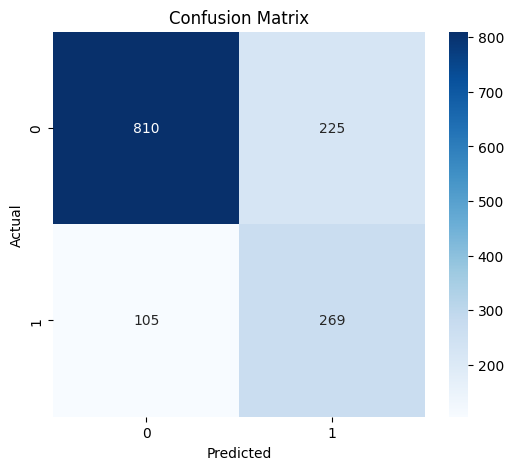

In [61]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [62]:
results.to_csv(
    "churn_predictions.csv",
    index=False
)

print("Predictions exported successfully!")

Predictions exported successfully!
